# Lab 12 — Transformers

**Name:** Omar Hejazi
**Student ID:** 2230009001

The task (four parts) is answered at the end. The lab's own cells are kept unchanged above it,
with analysis added underneath each one.

Two things worth knowing before reading the attention results:

- **`model.set_attn_implementation("eager")` is load-bearing, not decoration.** The default
  implementation is `sdpa`, which uses a fused kernel that never materialises the attention
  matrix. With it, `output_attentions=True` returns an *empty* tuple and `outputs.attentions[0]`
  raises `IndexError: tuple index out of range`. The line is what makes everything after it
  possible.
- **The sentence in the task is 11 tokens, not 7 words.** WordPiece splits `self-attention` into
  `self`, `-`, `attention`, so the attention matrix is 11×11. Counting words gives the wrong
  shape.

Every number quoted in the written sections comes from the executed cells below.

# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

C:\Users\Hadi-\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 29708.34it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768


DistilBERT reports **6 layers, 12 heads per layer, hidden size 768**. Two notes on reading those
numbers.

The 12 heads do not each get 768 dimensions. The hidden size is split across them — 768 / 12 = 64
dimensions per head — so the heads are cheap in parallel rather than 12 copies of the full model.
The concatenated head outputs are what add back up to 768.

DistilBERT has 6 layers because it is a distilled model: BERT-base has 12, and DistilBERT was
trained to reproduce BERT's behaviour with half the depth. The task at the end uses
`bert-base-uncased`, so these numbers are a useful comparison — same width and same head count
per layer, twice the depth.

Also worth noting that the attribute names here (`n_layers`, `n_heads`, `dim`) are
DistilBERT-specific. BERT's config calls them `num_hidden_layers`, `num_attention_heads` and
`hidden_size`, which matters in part 1 of the task.

<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


Eight tokens for a five-word sentence. `[CLS]` and `[SEP]` are added by the tokenizer: `[CLS]` is
the position whose final representation the classification head reads, and `[SEP]` marks the end
of the segment. The full stop is its own token too.

Every word here survived intact because all five are common enough to be in the 30,522-entry
WordPiece vocabulary. That is not guaranteed, and the task's sentence is a case where it does not
hold — shown there.

## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


### Reading that matrix

`Embeddings shape: torch.Size([1, 8, 768])` is (batch, tokens, hidden) — one 768-number vector
per token, before any attention has been applied. These are embeddings only: token embedding plus
position embedding, passed through a LayerNorm. They carry no context yet, so `not` and `good`
here know nothing about each other.

`Attention shape: torch.Size([8, 8])` is tokens × tokens, for **one** head of **one** layer. The
full tensor is `outputs.attentions`, a 6-tuple (one per layer) of `(1, 12, 8, 8)` tensors, so the
cell above is displaying 1 of the 72 attention matrices this model computed.

The orientation is the part that is easy to get backwards, and part 4 of the task asks about it
directly:

- **row *i*** = the token doing the attending (the *query*). Row *i* is "where token *i* looks".
- **column *j*** = the token being attended to (the *key*).
- so entry (*i*, *j*) is how much token *i* draws from token *j*.

Rows sum to 1 and columns do not, because the softmax is taken over the key dimension. The next
cell checks that rather than taking it on trust — it is the quickest way to confirm which axis is
which.

In [5]:
# Which axis is normalised tells you which axis is the query.
print("row sums   :", [round(float(x), 4) for x in attention.sum(dim=-1)])
print("column sums:", [round(float(x), 4) for x in attention.sum(dim=0)])
print()
print("full attention tensor:", len(outputs.attentions), "layers x",
      tuple(outputs.attentions[0].shape), "(batch, heads, tokens, tokens)")
print("total attention matrices in one forward pass:",
      len(outputs.attentions) * outputs.attentions[0].shape[1])

row sums   : [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
column sums: [2.3504, 0.5995, 0.5403, 0.72, 0.8959, 0.7446, 0.8471, 1.3023]

full attention tensor: 6 layers x (1, 12, 8, 8) (batch, heads, tokens, tokens)
total attention matrices in one forward pass: 72


Every row sums to exactly 1.0; the column sums are nothing in particular. So rows are queries,
confirmed from the data rather than from the diagram.

72 attention matrices in a single forward pass of this small model — 6 layers × 12 heads. Picking
`attentions[0][0, 0]`, as the lab does, means looking at one of them, and the task's part 3 asks
for a specific different one.

## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [6]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))

Prediction: NEGATIVE
Confidence: 1.0


`Confidence: 1.0` is a rounding artefact. `round(probs[prediction].item(), 3)` was applied to
0.999773, and no softmax over two classes with finite logits can return exactly 1. The model is
very confident, not certain, and printing a probability as `1.0` is the kind of thing worth
catching before it ends up in a report.

The prediction itself is correct and not trivially so — the sentence is *"The movie was not
good"*, where the only sentiment-bearing word is `good`, a positive one. Getting NEGATIVE
requires using `not`, which is exactly the contextual information self-attention provides. The
next cell checks that this is really what is happening.

In [7]:
# If the model is using the negation, flipping or removing it should flip the label.
for text in ["The movie was good.",
             "The movie was not good.",
             "The movie was not bad.",
             "The movie was bad."]:
    encoded = tokenizer(text, return_tensors="pt")
    with torch.no_grad():
        p = torch.softmax(model(**encoded).logits, dim=1)[0]
    label = model.config.id2label[int(p.argmax())]
    print(f"{text!r:32} {label:9} {float(p.max()):.4f}")

'The movie was good.'            POSITIVE  0.9999
'The movie was not good.'        NEGATIVE  0.9998
'The movie was not bad.'         POSITIVE  0.9987


'The movie was bad.'             NEGATIVE  0.9998


| Sentence | Label | Confidence |
|---|---|---|
| The movie was good. | POSITIVE | 0.9999 |
| The movie was not good. | NEGATIVE | 0.9998 |
| The movie was not bad. | POSITIVE | 0.9987 |
| The movie was bad. | NEGATIVE | 0.9998 |

All four correct, and the two negated cases are the interesting ones: `not good` → NEGATIVE and
`not bad` → POSITIVE. A bag-of-words model cannot do this, because `good` and `not` both simply
appear in the sentence; the label depends on them being adjacent in that order.

`not bad` is also the lowest-confidence row of the four (0.9987). That is a reasonable thing for
the model to be least sure about — "not bad" is a lukewarm compliment, so the positive label is
right but weaker than for a plain "good".

### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Task — answers

### Setup

Two choices to justify before the numbers.

**`AutoModel`, not `AutoModelForSequenceClassification`.** The task says to load the pretrained
`bert-base-uncased`, and that checkpoint has no classification head — it was pretrained on masked
language modelling and next-sentence prediction. Loading it through
`AutoModelForSequenceClassification` prints a load report saying `classifier.weight | MISSING`
and gives the model a **randomly initialised** head with the placeholder labels `LABEL_0` and
`LABEL_1`. Any prediction from it would be noise. Since this task only needs layers, heads and
attention weights, `AutoModel` gives the encoder without inventing a head.

**`eager` attention.** As noted at the top, the default `sdpa` implementation returns no
attention matrices at all.

In [8]:
from transformers import AutoTokenizer, AutoModel

bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name)
bert_model.eval()

print("default attention implementation:", bert_model.config._attn_implementation)

# Without this, output_attentions=True returns an empty tuple.
bert_model.set_attn_implementation("eager")
print("after switching            :", bert_model.config._attn_implementation)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   4%|▍         | 8/199 [00:00<00:03, 57.40it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 998.00it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


default attention implementation: sdpa
after switching            : eager


In [9]:
# 1. Number of Transformer layers and attention heads per layer.
n_layers = bert_model.config.num_hidden_layers
n_heads = bert_model.config.num_attention_heads

print("Transformer layers      :", n_layers)
print("Attention heads per layer:", n_heads)
print("Hidden size             :", bert_model.config.hidden_size)
print("Dimensions per head     :", bert_model.config.hidden_size // n_heads)

# 2. Total attention heads across all layers.
print()
print(f"Total attention heads   : {n_layers} x {n_heads} = {n_layers * n_heads}")

Transformer layers      : 12
Attention heads per layer: 12
Hidden size             : 768
Dimensions per head     : 64

Total attention heads   : 12 x 12 = 144


### Parts 1 and 2 — answers

- Transformer layers: **12**
- Attention heads per layer: **12**
- **Total attention heads: 12 × 12 = 144**

Hidden size is 768, so each head works in 768 / 12 = **64 dimensions**. The 144 heads are not 144
full-width attention mechanisms; they are 12 layers of 12 narrow ones, and the per-layer cost is
roughly that of a single 768-dimensional attention.

Compared with the DistilBERT above: same width (768), same heads per layer (12), twice the depth
(12 vs 6), so 144 heads against 72.

In [10]:
# 3. Attention from the THIRD layer, SECOND head.
sentence = "Transformers use self-attention to understand language."
encoded = bert_tokenizer(sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(encoded["input_ids"][0])

print("tokens:", bert_tokens)
print("token count:", len(bert_tokens), "(the sentence has 7 words)")

with torch.no_grad():
    bert_out = bert_model(**encoded, output_attentions=True)

# The task counts from 1; Python counts from 0. Third layer -> index 2, second head -> index 1.
LAYER, HEAD = 3, 2
attn = bert_out.attentions[LAYER - 1][0, HEAD - 1]

print()
print(f"attentions tuple length      : {len(bert_out.attentions)} (one per layer)")
print(f"each layer's tensor shape    : {tuple(bert_out.attentions[0].shape)}")
print(f"layer {LAYER}, head {HEAD} matrix shape : {tuple(attn.shape)}")
print()
print("attention weights:")
print(attn)

tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
token count: 11 (the sentence has 7 words)

attentions tuple length      : 12 (one per layer)
each layer's tensor shape    : (1, 12, 11, 11)
layer 3, head 2 matrix shape : (11, 11)

attention weights:
tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1289e-02, 6.3943e-01, 1.2104e-02, 1.2819e-02,
 

### Part 3 — notes

**The indexing.** "Third layer, second head" means `attentions[2][0, 1]`: the tuple is indexed
from 0, so layer 3 is index 2, and head 2 is index 1. Writing `attentions[3][0, 2]` would quietly
return the *fourth* layer's *third* head — a wrong answer that looks completely normal, since
every one of these matrices is a plausible 11×11 row-stochastic matrix. There is nothing in the
output to tell you that you fetched the wrong one.

**The shape is 11×11, not 7×7.** The sentence has 7 words but tokenises to 11 tokens:

```
['[CLS]', 'transformers', 'use', 'self', '-', 'attention',
 'to', 'understand', 'language', '.', '[SEP]']
```

`self-attention` is not in BERT's 30,522-token vocabulary, so WordPiece breaks it into `self`,
`-`, `attention` — three tokens for one word. Together with `[CLS]`, `[SEP]` and the full stop,
that is 11. Any attempt to label the axes with the original words will be misaligned from token 4
onward.

In [11]:
# Where does each token actually send its attention in this head?
print(f'{"token (query)":16} {"attends most to":16} weight')
for i, token in enumerate(bert_tokens):
    j = int(attn[i].argmax())
    print(f"{token:16} {bert_tokens[j]:16} {float(attn[i, j]):.3f}")

sep_index = bert_tokens.index("[SEP]")
print()
print(f"average attention paid to [CLS] : {float(attn[:, 0].mean()):.3f}")
print(f"average attention paid to [SEP] : {float(attn[:, sep_index].mean()):.3f}")
print(f"average self-attention (diagonal): {float(attn.diag().mean()):.3f}")

token (query)    attends most to  weight
[CLS]            [CLS]            0.732
transformers     [CLS]            0.889
use              transformers     0.569
self             [CLS]            0.340
-                self             0.639
attention        transformers     0.545
to               use              0.622
understand       [CLS]            0.434
language         use              0.429
.                [CLS]            0.658
[SEP]            [CLS]            0.828

average attention paid to [CLS] : 0.401
average attention paid to [SEP] : 0.093
average self-attention (diagonal): 0.091


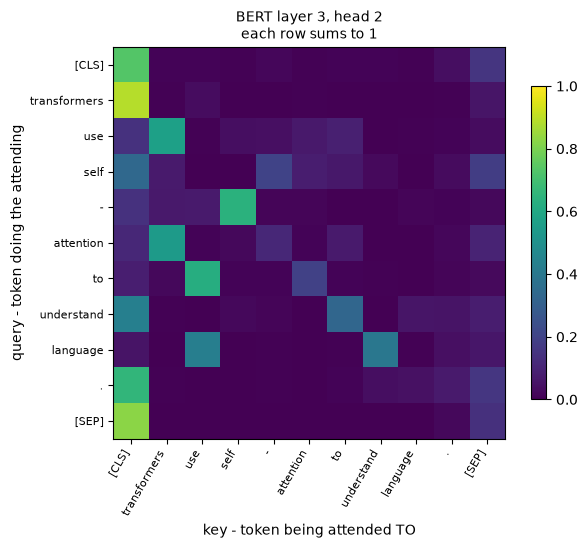

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.4, 5.4))
im = ax.imshow(attn.numpy(), cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(bert_tokens)))
ax.set_yticks(range(len(bert_tokens)))
ax.set_xticklabels(bert_tokens, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(bert_tokens, fontsize=8)
ax.set_xlabel("key - token being attended TO")
ax.set_ylabel("query - token doing the attending")
ax.set_title(f"BERT layer {LAYER}, head {HEAD}\neach row sums to 1", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [13]:
# How common is the "attend to a structural token" behaviour across all 144 heads?
import torch

cls_mass, sep_mass = [], []
for layer in range(n_layers):
    for head in range(n_heads):
        M = bert_out.attentions[layer][0, head]
        cls_mass.append((float(M[:, 0].mean()), layer + 1, head + 1))
        sep_mass.append((float(M[:, sep_index].mean()), layer + 1, head + 1))

heavy = sum(1 for m, _, _ in cls_mass if m > 0.5) + sum(1 for m, _, _ in sep_mass if m > 0.5)
print(f"heads sending over half their attention to [CLS] or [SEP]: {heavy} of {len(cls_mass)}")
print()
print("top 3 heads by attention to [CLS]:")
for m, l, h in sorted(cls_mass, reverse=True)[:3]:
    print(f"   layer {l:2} head {h:2}: {m:.3f}")
print("top 3 heads by attention to [SEP]:")
for m, l, h in sorted(sep_mass, reverse=True)[:3]:
    print(f"   layer {l:2} head {h:2}: {m:.3f}")
print()
print(f"layer 12 head 1 -> [SEP]: {sep_mass[(12 - 1) * n_heads + 0][0]:.3f}")
print(f"layer  3 head 2 -> [CLS]: {cls_mass[(3 - 1) * n_heads + 1][0]:.3f}")

heads sending over half their attention to [CLS] or [SEP]: 72 of 144

top 3 heads by attention to [CLS]:
   layer  2 head  7: 0.912
   layer  2 head  4: 0.751
   layer  2 head  3: 0.616
top 3 heads by attention to [SEP]:
   layer 12 head  8: 0.956
   layer 12 head 12: 0.943
   layer 12 head  1: 0.886

layer 12 head 1 -> [SEP]: 0.886
layer  3 head 2 -> [CLS]: 0.401


In [14]:
# The claim that bert-base-uncased has no usable classification head, demonstrated.
from transformers import AutoModelForSequenceClassification

classifier_version = AutoModelForSequenceClassification.from_pretrained(bert_name)
print("label map:", classifier_version.config.id2label)
print("classifier head was in the checkpoint:",
      "classifier.weight" in AutoModel.from_pretrained(bert_name).state_dict())
print("head weight std (randomly initialised):",
      round(float(classifier_version.classifier.weight.std()), 5))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  13%|█▎        | 25/199 [00:00<00:00, 249.77it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1873.68it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


label map: {0: 'LABEL_0', 1: 'LABEL_1'}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   1%|          | 2/199 [00:00<00:10, 19.53it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1801.24it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


classifier head was in the checkpoint: False
head weight std (randomly initialised): 0.02017


### Part 4 — what the rows and columns represent

**Rows are queries, columns are keys.** Row *i* is the distribution token *i* spreads over the
whole sentence when deciding what to read; entry (*i*, *j*) is the weight token *i* puts on token
*j*. The new representation of token *i* is the weighted average of all tokens' value vectors
using row *i* as the weights.

**Rows sum to 1, columns do not.** The softmax runs along the key axis, which is what makes each
row a probability distribution. Checking which axis sums to 1 is the reliable way to tell the two
apart, and the earlier cell did exactly that for DistilBERT.

**It is not symmetric.** Entry (*i*, *j*) and (*j*, *i*) are unrelated — `use` can draw heavily on
`transformers` without the reverse holding. Attention is directed.

**What this particular head does**, from the output above:

| Query | Attends most to | Weight |
|---|---|---|
| `use` | `transformers` | 0.569 |
| `-` | `self` | 0.639 |
| `attention` | `transformers` | 0.545 |
| `to` | `use` | 0.622 |
| `language` | `use` | 0.429 |

Some of this looks genuinely syntactic. `use` is the main verb and it attends to `transformers`,
its subject. `to` attends to `use`, the verb it depends on. The hyphen attends to `self`, the
piece it was split from, which is the model reassembling a word WordPiece tore apart.

**But the single largest effect is not linguistic at all.** This head sends **40.1%** of its
attention mass, on average, to `[CLS]` — and for five of the eleven tokens (`transformers`,
`self`, `understand`, `.`, `[SEP]`) `[CLS]` is the top target, with `transformers` putting 0.889
there. Average self-attention on the diagonal is only 0.091.

`[CLS]` carries no content of its own at this depth, so attending to it is close to a no-op: it is
how a head declines to do anything on this input. This is a well-documented behaviour in BERT,
often called an attention sink.

The scan over all 144 heads puts a number on how widespread it is: **72 of 144 heads — exactly
half — send more than 50% of their attention to `[CLS]` or `[SEP]` on this sentence.** The
extremes are stark. Layer 2 head 7 puts 0.912 on `[CLS]`; layer 12 head 8 puts 0.956 on `[SEP]`,
and layer 12's first head 0.886. Deep layers are where `[SEP]` dominates.

The practical conclusion: a single head's matrix is not an explanation of the model. Half the
heads are idling on this input, and the interpretable patterns in the table above sit alongside a
much larger flow of attention into tokens that mean nothing. Picking one head and reading a story
off it is easy to do and easy to get wrong — and with 144 to choose from, a head supporting
almost any story can be found.

# Summary

**Task answers**

1. `bert-base-uncased` has **12 layers** and **12 attention heads per layer** (hidden size 768,
   so 64 dimensions per head).
2. **144 attention heads** in total.
3. Third layer, second head is `attentions[2][0, 1]` — 1-indexed in the question, 0-indexed in
   Python. The matrix is **11×11**, because `self-attention` tokenises to `self`, `-`,
   `attention`, giving 11 tokens for a 7-word sentence.
4. **Rows are the attending token (query), columns the token attended to (key).** Entry (*i*,
   *j*) is how much token *i* draws from token *j*. Rows sum to 1 because the softmax is over the
   key axis; columns do not, and the matrix is not symmetric.

**What the attention actually showed**

Some of this head's behaviour is interpretable: `use` → `transformers` (verb to its subject,
0.569), `to` → `use` (0.622), `-` → `self` (0.639, reattaching a word WordPiece split). But 40.1%
of its average attention mass goes to `[CLS]`, a token with no content, against 0.091 average
self-attention.

Scanning all 144 heads shows this is the norm, not an oddity of the head the task picked:
**exactly half of them — 72 of 144 — send more than 50% of their attention to `[CLS]` or
`[SEP]`**, peaking at 0.912 (layer 2 head 7, to `[CLS]`) and 0.956 (layer 12 head 8, to `[SEP]`).
A head that dumps its attention on a structural token is effectively idling, so one matrix read in
isolation is weak evidence about what the model is doing.

**Two traps in the lab's code, both of which fail quietly**

- The default attention implementation is `sdpa`, which never builds the attention matrix.
  `output_attentions=True` then yields an empty tuple and an `IndexError` on the next line.
  `set_attn_implementation("eager")` is what makes the whole exercise work.
- `Confidence: 1.0` in section 4 is `round(0.999773, 3)`. The model is confident, not certain,
  and a probability printed as exactly 1.0 should always be treated as a formatting bug.

**A note on `bert-base-uncased` and classification heads**

`bert-base-uncased` ships with no classification head. Loading it through
`AutoModelForSequenceClassification` prints `classifier.weight | MISSING`, initialises the head
randomly (weight std 0.020) and labels the outputs `LABEL_0` / `LABEL_1` — so any prediction from
it is noise. `AutoModel` is the right loader when only the encoder is needed.

**On the demo model**

DistilBERT classifies all four of my test sentences correctly, including `not good` → NEGATIVE and
`not bad` → POSITIVE. Those two are the ones that need context rather than vocabulary, which is
the case for self-attention in one line. `not bad` draws the lowest confidence of the four
(0.9987), which is the right sentence to be least certain about.